# Model 1 : State of Health (SOH %) prediction

### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import joblib

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Load dataset

In [4]:
df=pd.read_csv("../dataset/ev_battery_health.csv")

In [5]:
df.head()

,battery_id,observation_id,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,manufacture_date,observation_date,battery_age_days,cycle_count,...,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,last_service_date,bms_firmware_version,recall_flag,state_of_health_pct,remaining_useful_life_cycles,failure_risk_label,degradation_category
0,BATT_01748,OBS_033554,LMO,StormCell,Crossover-X2,48.5,2022-11-23,2024-10-16,693.0,991.0,...,-1.3,19.13,4.0,2023-12-25,BMS_v2.1,0.0,80.87,0,High,Normal
1,BATT_00491,OBS_009428,LFP,VoltaCore,Sedan-E1,61.5,2023-03-06,2024-12-27,662.0,1535.0,...,5.3,8.19,0.0,NaN,BMS_v3.2,0.0,91.81,1739,Low,Normal
2,BATT_00011,OBS_000200,LFP,IonFlux,Van-E4,73.1,2025-06-24,2026-02-10,NaN,407.0,...,21.3,2.52,0.0,NaN,NaN,0.0,97.48,3248,Low,Normal
3,BATT_00651,OBS_012448,NMC,Amperion,NaN,75.6,2022-08-13,2022-09-15,33.0,29.0,...,20.8,0.82,0.0,NaN,BMS_v3.5,0.0,99.18,1375,Low,Normal
4,BATT_02054,OBS_039490,NCA,VoltaCore,Hatch-E3,92.7,2024-09-27,2026-03-01,520.0,324.0,...,40.1,8.14,0.0,NaN,BMS_v2.1,0.0,91.86,715,Low,Normal


In [6]:
df.shape

(50000, 35)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   battery_id                      50000 non-null  object 
 1   observation_id                  50000 non-null  object 
 2   chemistry                       46541 non-null  object 
 3   manufacturer                    47539 non-null  object 
 4   vehicle_model                   46485 non-null  object 
 5   pack_capacity_kwh               47698 non-null  float64
 6   manufacture_date                48090 non-null  object 
 7   observation_date                47784 non-null  object 
 8   battery_age_days                46998 non-null  float64
 9   cycle_count                     47731 non-null  float64
 10  climate_zone                    47281 non-null  object 
 11  avg_daily_distance_km           47882 non-null  float64
 12  avg_charging_power_kw           

In [8]:
df.describe().round(1)

,pack_capacity_kwh,battery_age_days,cycle_count,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,avg_depth_of_discharge_pct,avg_state_of_charge_pct,charge_cycles_per_month,total_energy_throughput_kwh,...,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,capacity_fade_pct,service_count,recall_flag,state_of_health_pct,remaining_useful_life_cycles
count,47698.0,46998.0,47731.0,47882.0,47860.0,46595.0,47168.0,46862.0,47946.0,46630.0,...,47896.0,47193.0,47513.0,47909.0,47872.0,48131.0,48400.0,47354.0,50000.0,50000.0
mean,72.7,561.2,570.5,50.2,32.1,0.3,64.9,67.6,20.1,38510.4,...,49.2,363.9,137.8,126.1,26.6,7.1,1.4,0.0,92.9,1491.2
std,14.5,479.6,600.0,39.5,17.8,0.2,15.7,10.1,10.2,42274.0,...,21.3,12.3,20.0,108.9,12.9,7.1,1.7,0.1,7.1,1213.9
min,40.0,1.0,1.0,3.0,0.9,0.0,10.0,30.9,2.0,36.4,...,7.7,318.5,25.3,5.5,-10.9,0.0,0.0,0.0,55.0,0.0
25%,62.5,169.0,137.0,22.5,19.1,0.2,54.1,60.7,12.6,8857.7,...,34.8,355.2,125.1,61.0,17.8,2.0,0.0,0.0,90.1,600.0
50%,72.6,424.0,371.0,39.3,28.8,0.3,65.1,67.8,18.9,24134.4,...,43.1,365.6,137.3,94.4,26.8,4.8,1.0,0.0,95.2,1142.0
75%,82.8,846.0,801.0,66.1,42.0,0.4,75.9,74.6,26.4,53339.4,...,57.0,373.0,150.1,150.4,35.6,9.9,2.0,0.0,98.0,2322.0
max,100.0,2184.0,5073.0,400.0,159.6,0.9,100.0,95.0,57.5,402419.9,...,307.1,402.8,291.8,1232.4,93.6,45.0,15.0,1.0,100.0,5928.0


### Remove unnecessary columns

In [9]:
drop_columns=['battery_id', 'observation_id','manufacture_date',
       'observation_date', 'remaining_useful_life_cycles', 'failure_risk_label',
       'degradation_category' ,'last_service_date', 'capacity_fade_pct',]
df=df.drop(drop_columns,axis=1)
df.shape

(50000, 26)

In [10]:
df.columns

Index(['chemistry', 'manufacturer', 'vehicle_model', 'pack_capacity_kwh',
       'battery_age_days', 'cycle_count', 'climate_zone',
       'avg_daily_distance_km', 'avg_charging_power_kw', 'fast_charge_ratio',
       'avg_depth_of_discharge_pct', 'avg_state_of_charge_pct',
       'charge_cycles_per_month', 'total_energy_throughput_kwh',
       'avg_ambient_temp_c', 'humidity_pct', 'altitude_m',
       'internal_resistance_mohm', 'voltage_avg_v', 'current_avg_a',
       'charge_time_avg_min', 'peak_temp_during_fast_charge_c',
       'service_count', 'bms_firmware_version', 'recall_flag',
       'state_of_health_pct'],
      dtype='object')

### Remove duplicate rows

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df=df.drop_duplicates()
df.shape

(50000, 26)

### Missing values

In [13]:
df.isnull().sum()

chemistry                         3459
manufacturer                      2461
vehicle_model                     3515
pack_capacity_kwh                 2302
battery_age_days                  3002
cycle_count                       2269
climate_zone                      2719
avg_daily_distance_km             2118
avg_charging_power_kw             2140
fast_charge_ratio                 3405
avg_depth_of_discharge_pct        2832
avg_state_of_charge_pct           3138
charge_cycles_per_month           2054
total_energy_throughput_kwh       3370
avg_ambient_temp_c                3282
humidity_pct                      2737
altitude_m                        2322
internal_resistance_mohm          2104
voltage_avg_v                     2807
current_avg_a                     2487
charge_time_avg_min               2091
peak_temp_during_fast_charge_c    2128
service_count                     1600
bms_firmware_version              2328
recall_flag                       2646
state_of_health_pct      

In [14]:
# numeric columns -> fill with median
num_col=df.select_dtypes(include="number").columns
for col in num_col:
    df[col]=df[col].fillna(df[col].median())
# text columns -> fill with most common value (mode)
cat_col=df.select_dtypes(exclude="number").columns
for col in cat_col:
    df[col]=df[col].fillna(df[col].mode()[0])

In [15]:
df.isnull().sum()

chemistry                         0
manufacturer                      0
vehicle_model                     0
pack_capacity_kwh                 0
battery_age_days                  0
cycle_count                       0
climate_zone                      0
avg_daily_distance_km             0
avg_charging_power_kw             0
fast_charge_ratio                 0
avg_depth_of_discharge_pct        0
avg_state_of_charge_pct           0
charge_cycles_per_month           0
total_energy_throughput_kwh       0
avg_ambient_temp_c                0
humidity_pct                      0
altitude_m                        0
internal_resistance_mohm          0
voltage_avg_v                     0
current_avg_a                     0
charge_time_avg_min               0
peak_temp_during_fast_charge_c    0
service_count                     0
bms_firmware_version              0
recall_flag                       0
state_of_health_pct               0
dtype: int64

### Outlier analysis

In [16]:
# numeric input columns (skip the target and 0/1 columns)
outlier_cols = [col for col in num_col if col != "state_of_health_pct" and df[col].nunique() > 2]
len(outlier_cols)

19

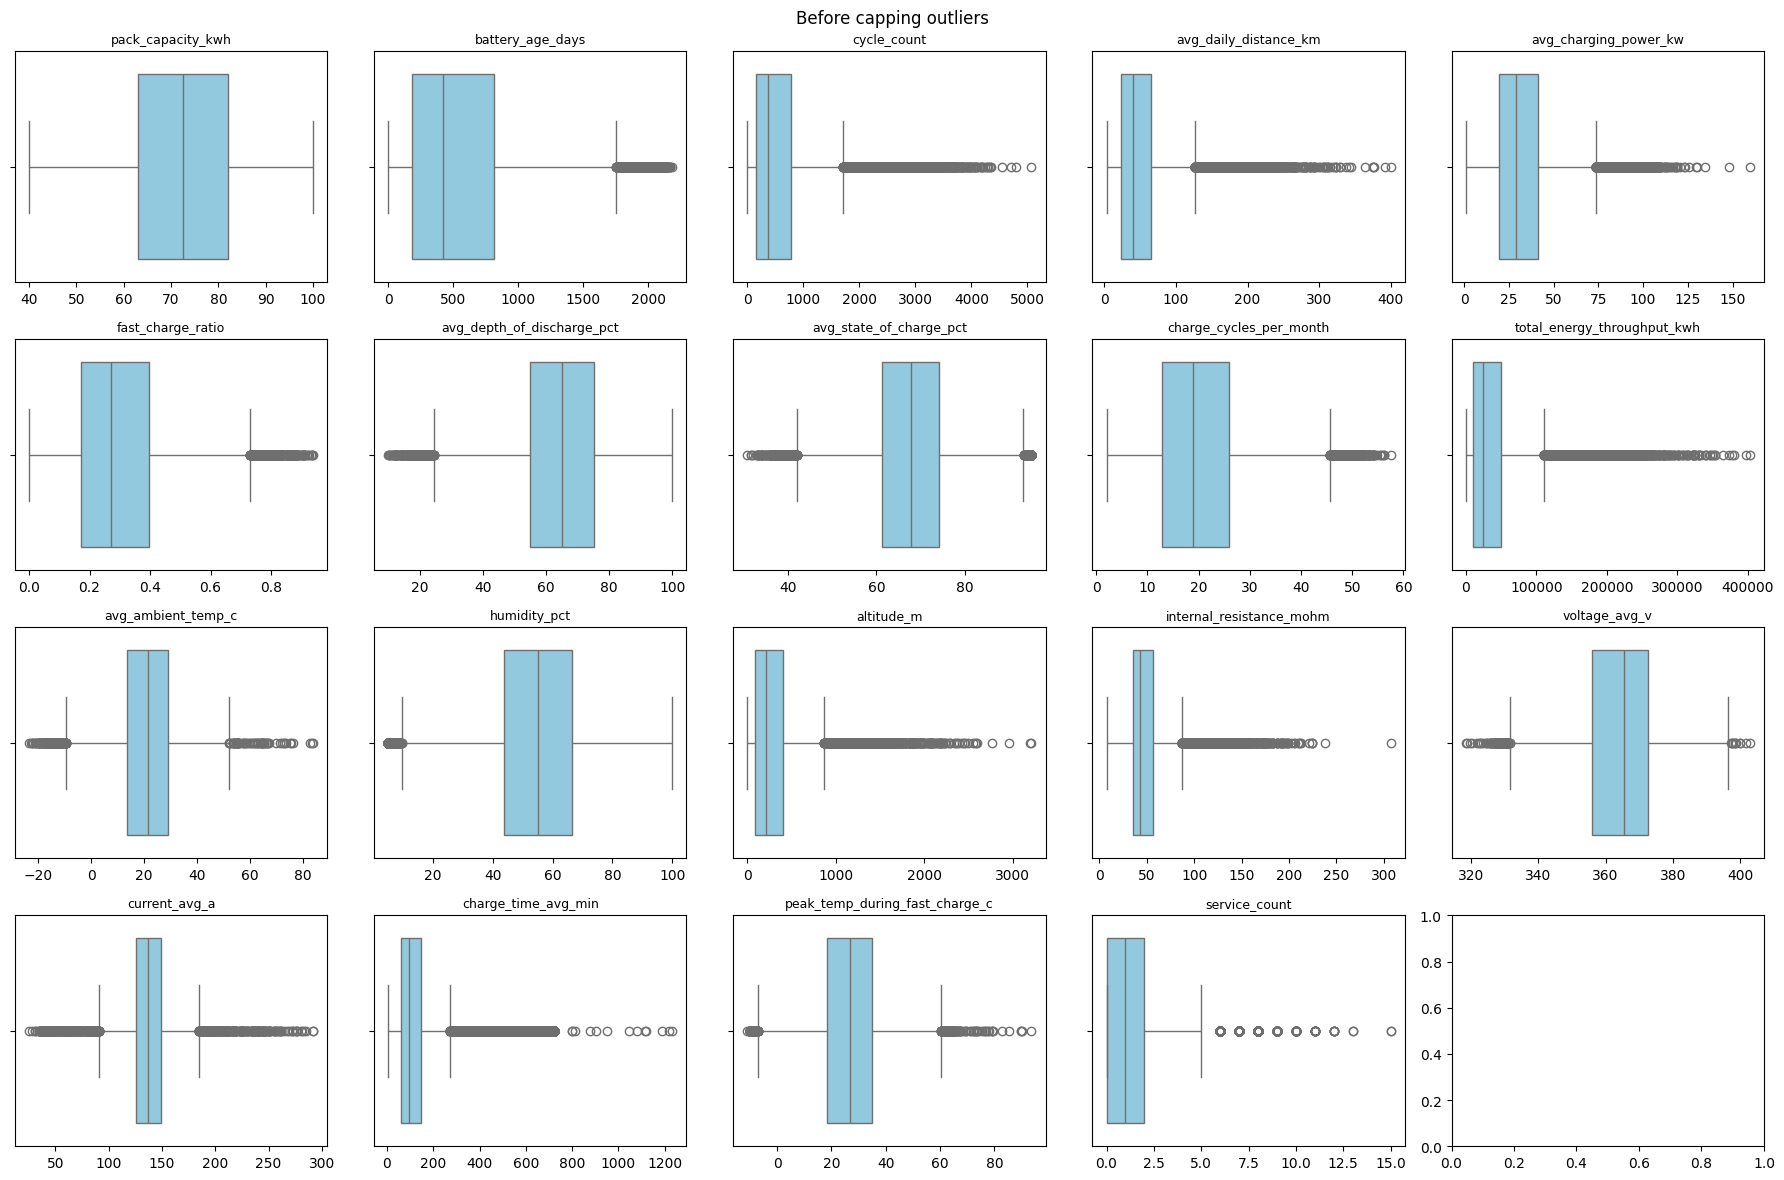

In [17]:
# boxplots before capping
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("Before capping outliers")
plt.tight_layout()
plt.show()
#This code is used to visualize numerical columns using boxplots before outlier capping.
#It helps to identify possible outliers and understand the data distribution before preprocessing.

In [18]:
# count outliers and cap them
for col in outlier_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:32s} outliers = {outliers}")
    df[col] = df[col].clip(lower, upper)

pack_capacity_kwh                outliers = 0
battery_age_days                 outliers = 1015
cycle_count                      outliers = 2757
avg_daily_distance_km            outliers = 2499
avg_charging_power_kw            outliers = 1436
fast_charge_ratio                outliers = 552
avg_depth_of_discharge_pct       outliers = 265
avg_state_of_charge_pct          outliers = 506
charge_cycles_per_month          outliers = 660
total_energy_throughput_kwh      outliers = 3107
avg_ambient_temp_c               outliers = 410
humidity_pct                     outliers = 283
altitude_m                       outliers = 2641
internal_resistance_mohm         outliers = 2940
voltage_avg_v                    outliers = 161
current_avg_a                    outliers = 894
charge_time_avg_min              outliers = 3585
peak_temp_during_fast_charge_c   outliers = 322
service_count                    outliers = 1520


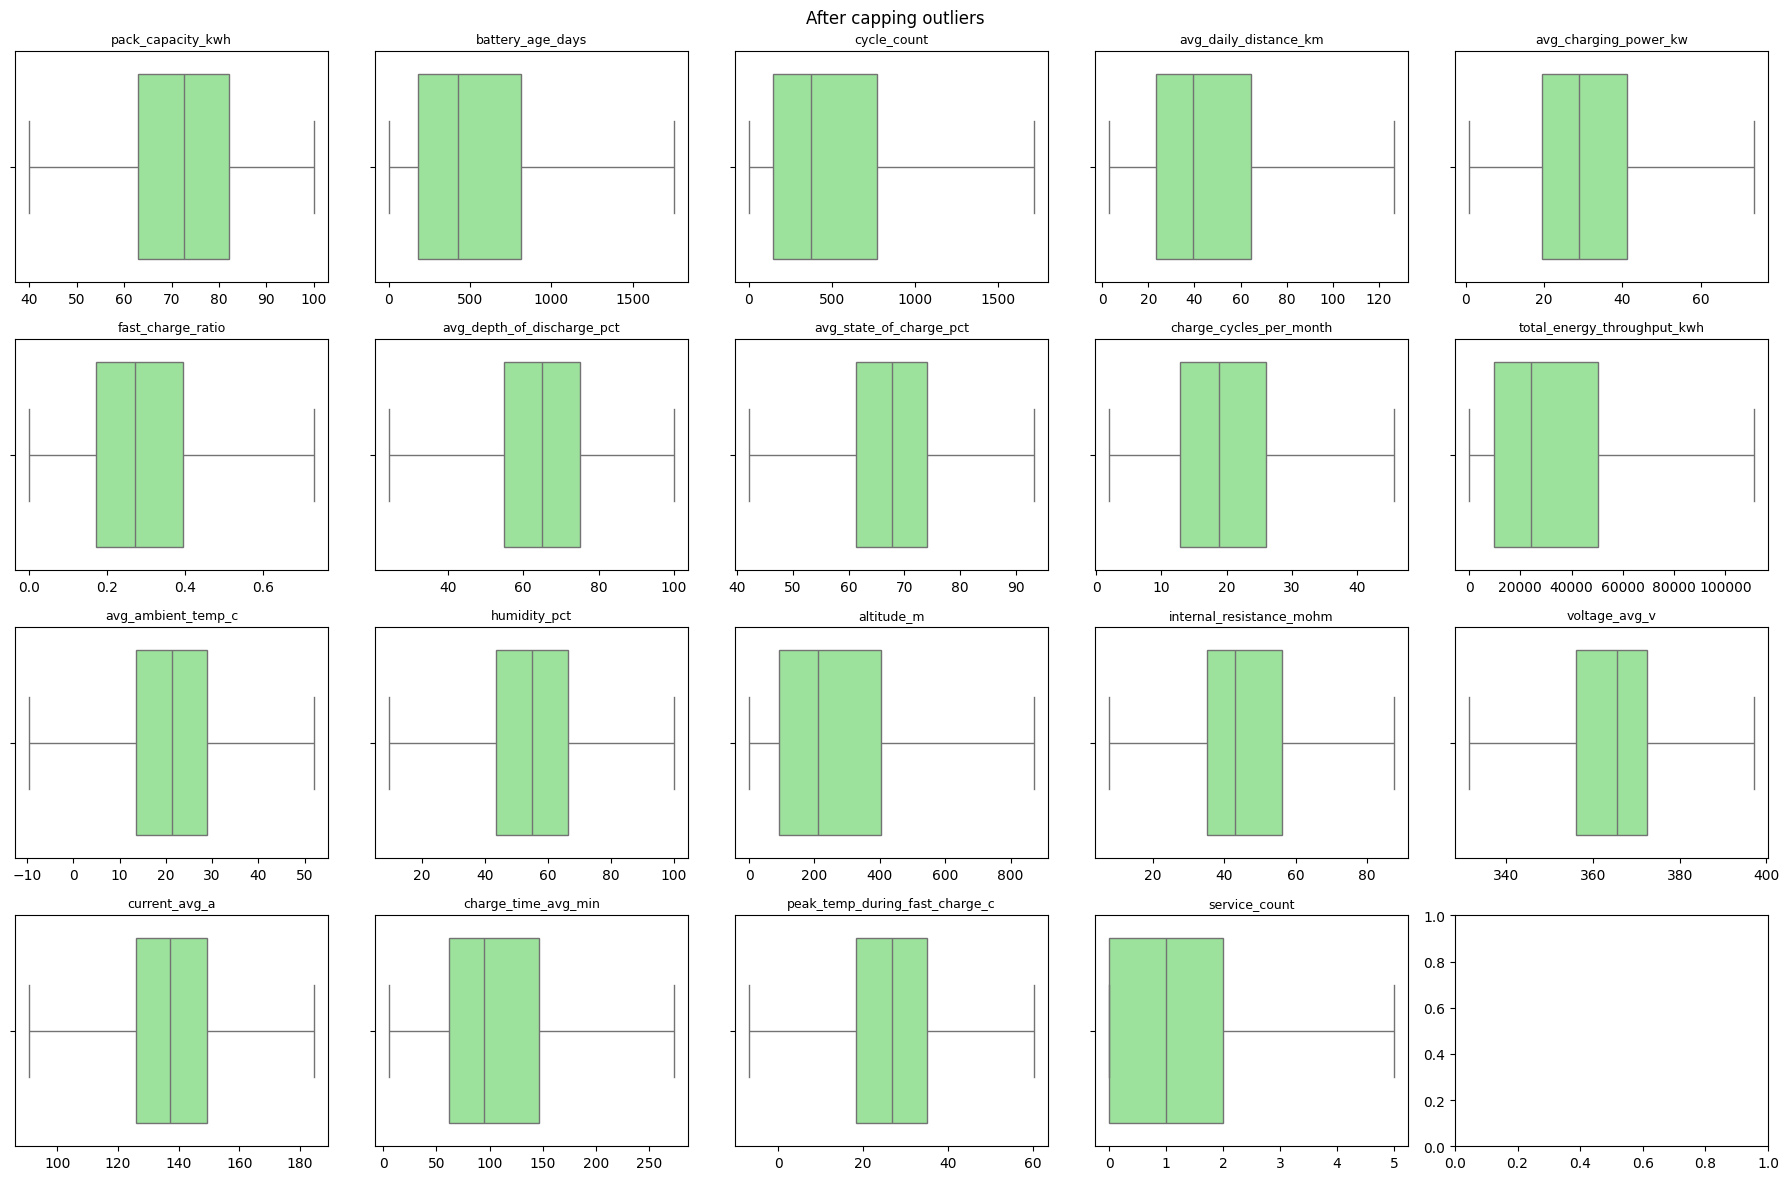

In [19]:
# boxplots after capping
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
for ax, col in zip(axes.flatten(), outlier_cols):
    sns.boxplot(x=df[col], ax=ax, color="lightgreen")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.suptitle("After capping outliers")
plt.tight_layout()
plt.show()

#This code is used to visualize multiple numerical columns using boxplots after outlier capping.
#It helps to check the distribution of data and identify any remaining possible outliers.

### EDA (Exploratory Data Analysis)

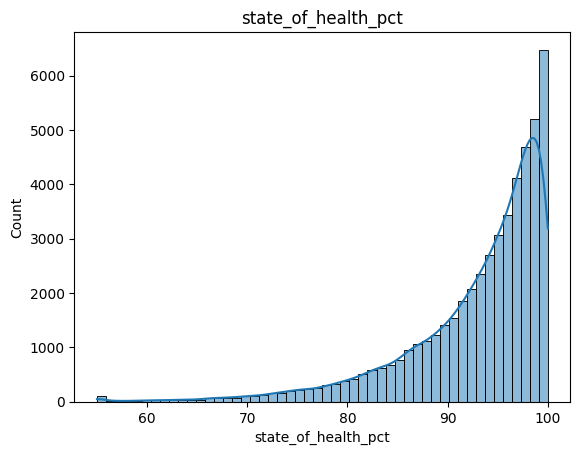

In [20]:
sns.histplot(df["state_of_health_pct"], bins=50, kde=True)
plt.title("state_of_health_pct")
plt.show()


#This code is used to visualize the distribution of the target variable state_of_health_pct using a histogram with a KDE curve.

In [21]:
co = df.corr(numeric_only=True)   # correlation between numeric columns

In [22]:
co["state_of_health_pct"].sort_values(ascending=False)   # correlation of every column with the target
#This code calculates the correlation of all numerical features with the target variable state_of_health_pct and
#sorts the results in descending order.It helps identify features that have strong positive or negative relationships with the target.

state_of_health_pct               1.000000
voltage_avg_v                     0.044718
pack_capacity_kwh                 0.038429
avg_ambient_temp_c                0.037448
peak_temp_during_fast_charge_c    0.035148
avg_state_of_charge_pct           0.027956
recall_flag                       0.003742
charge_time_avg_min               0.002952
altitude_m                        0.000310
humidity_pct                     -0.000081
avg_charging_power_kw            -0.003008
current_avg_a                    -0.003607
fast_charge_ratio                -0.004800
avg_depth_of_discharge_pct       -0.034385
avg_daily_distance_km            -0.167687
charge_cycles_per_month          -0.249864
service_count                    -0.566651
total_energy_throughput_kwh      -0.781877
battery_age_days                 -0.787631
cycle_count                      -0.834438
internal_resistance_mohm         -0.873273
Name: state_of_health_pct, dtype: float64

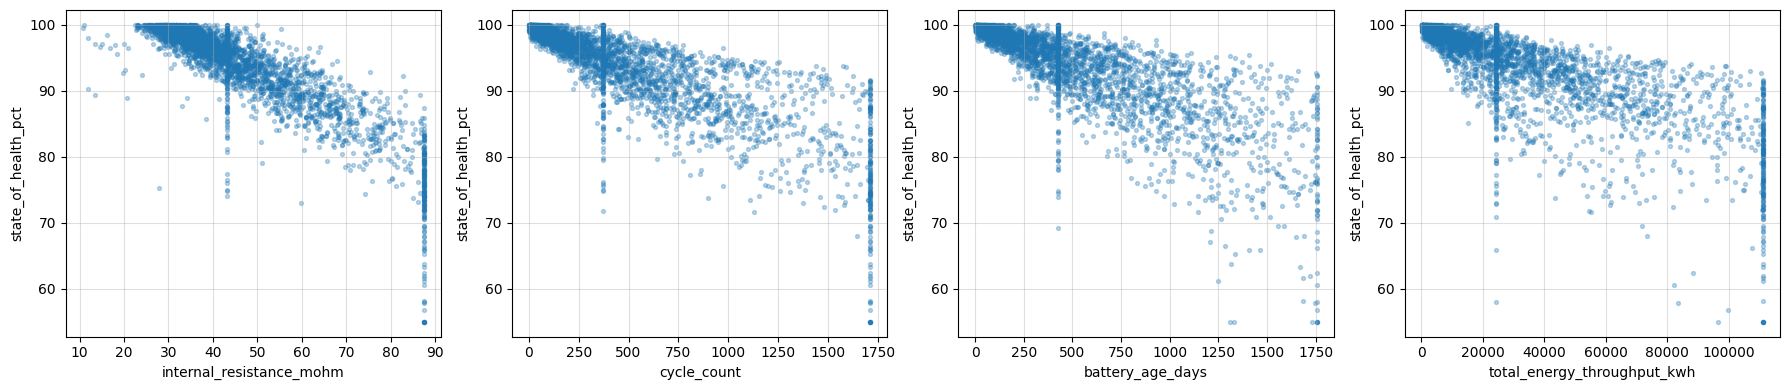

In [23]:
# scatter plot of the 4 most correlated columns with the target
features = co["state_of_health_pct"].drop("state_of_health_pct").abs().sort_values(ascending=False).head(4).index
sample = df.sample(3000, random_state=42)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    ax.scatter(sample[col], sample["state_of_health_pct"], alpha=0.3, s=8)
    ax.set_xlabel(col)
    ax.set_ylabel("state_of_health_pct")
    ax.grid(alpha=0.4)
plt.tight_layout()
plt.show()

#This code selects the four most correlated features with the target variable and creates scatter plots to visualize
#their relationships with state_of_health_pct. It uses 3000 random samples to make the graphs easier to understand.

### Encode text columns

In [24]:
cat_col

Index(['chemistry', 'manufacturer', 'vehicle_model', 'climate_zone',
       'bms_firmware_version'],
      dtype='object')

In [25]:
encoders = {}
for col in cat_col:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le   # keep the encoder so new data can be encoded the same way

In [26]:
df.head()

,chemistry,manufacturer,vehicle_model,pack_capacity_kwh,battery_age_days,cycle_count,climate_zone,avg_daily_distance_km,avg_charging_power_kw,fast_charge_ratio,...,altitude_m,internal_resistance_mohm,voltage_avg_v,current_avg_a,charge_time_avg_min,peak_temp_during_fast_charge_c,service_count,bms_firmware_version,recall_flag,state_of_health_pct
0,1,6,1,48.5,693.0,991.0,0,120.3,28.8,0.345,...,390.0,87.52,365.6,146.4,40.1,-1.3,4.0,0,0.0,80.87
1,0,7,5,61.5,662.0,1535.0,0,93.4,73.5,0.569,...,871.0,49.95,357.3,176.0,38.0,5.3,0.0,3,0.0,91.81
2,0,3,7,73.1,424.0,407.0,0,45.0,73.5,0.641,...,249.0,37.90,375.4,156.8,41.7,21.3,0.0,2,0.0,97.48
3,3,0,7,75.6,33.0,29.0,0,42.4,73.5,0.596,...,3.0,43.08,361.7,150.3,18.2,20.8,0.0,4,0.0,99.18
4,2,7,2,92.7,520.0,324.0,1,23.4,36.3,0.550,...,206.0,68.34,374.0,159.5,79.2,40.1,0.0,0,0.0,91.86


### Splitting into train and test

In [27]:
x=df.drop(["state_of_health_pct"],axis=1)
y=df["state_of_health_pct"]

In [28]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Training rows :", len(x_train))
print("Test rows :", len(x_test))

Training rows : 40000
Test rows : 10000


### Scaling

In [29]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

### Train the models

In [30]:
results = []   # we store the score of every model here
models = {}    # and the trained models here

### 1. Linear Regression

In [34]:
lr_model=LinearRegression()
lr_model.fit(x_train,y_train)
y_pred_lr=lr_model.predict(x_test)

In [36]:
mae = mean_absolute_error(y_test, y_pred_lr)
mse = mean_squared_error(y_test, y_pred_lr)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_lr)
train_r2 = lr_model.score(x_train, y_train)
print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Linear Regression", train_r2, r2, mae, rmse])
models["Linear Regression"] = lr_model


MAE = 1.69  MSE = 6.99  RMSE = 2.64  R2 = 0.862
Train R2 = 0.857  Test R2 = 0.862


### 2. Decision Tree

In [37]:
dt_model = DecisionTreeRegressor(max_depth=12, random_state=42)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dt)
train_r2 = dt_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Decision Tree", train_r2, r2, mae, rmse])
models["Decision Tree"] = dt_model

MAE = 1.01  MSE = 2.93  RMSE = 1.71  R2 = 0.942
Train R2 = 0.984  Test R2 = 0.942


### 3. Random Forest

In [38]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_rf)
train_r2 = rf_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Random Forest", train_r2, r2, mae, rmse])
models["Random Forest"] = rf_model

MAE = 0.80  MSE = 1.62  RMSE = 1.27  R2 = 0.968
Train R2 = 0.993  Test R2 = 0.968


### 4. Gradient Boosting

In [39]:
gb_model = GradientBoostingRegressor(n_estimators=200, random_state=42)
gb_model.fit(x_train, y_train)
y_pred_gb = gb_model.predict(x_test)

mae = mean_absolute_error(y_test, y_pred_gb)
mse = mean_squared_error(y_test, y_pred_gb)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_gb)
train_r2 = gb_model.score(x_train, y_train)

print(f"MAE = {mae:.2f}  MSE = {mse:.2f}  RMSE = {rmse:.2f}  R2 = {r2:.3f}")
print(f"Train R2 = {train_r2:.3f}  Test R2 = {r2:.3f}")

results.append(["Gradient Boosting", train_r2, r2, mae, rmse])
models["Gradient Boosting"] = gb_model

MAE = 0.82  MSE = 1.57  RMSE = 1.25  R2 = 0.969
Train R2 = 0.972  Test R2 = 0.969


### Compare the models
#### The best model has the highest test R2.

In [40]:
compare = pd.DataFrame(results, columns=["model", "train_r2", "test_r2", "mae", "rmse"])
compare = compare.sort_values("test_r2", ascending=False).round(2)
compare

,model,train_r2,test_r2,mae,rmse
3,Gradient Boosting,0.97,0.97,0.82,1.25
2,Random Forest,0.99,0.97,0.80,1.27
1,Decision Tree,0.98,0.94,1.01,1.71
0,Linear Regression,0.86,0.86,1.69,2.64


In [41]:
best_name = compare.iloc[0]["model"]
best_model = models[best_name]
print("Best model :", best_name)

Best model : Gradient Boosting


### Save the best mode

In [42]:
saved = {
    "model": models["Gradient Boosting"],
    "scaler": scaler,
    "encoders": encoders,
    "columns": list(x.columns),
}
joblib.dump(saved, "../models/soh_model.pkl", compress=3)
print("Saved : models/soh_model.pkl")

Saved : models/soh_model.pkl


### Test the saved model

In [43]:
loaded = joblib.load("../models/soh_model.pkl")
model = loaded["model"]

y_new = model.predict(x_test[0:5])   # predict the first 5 test rows
print("Predicted :", y_new)
print("Actual    :", np.array(y_test[0:5]))

Predicted : [98.52278523 74.96537882 96.81857833 92.82827207 94.61034889]
Actual    : [99.22 75.21 97.57 92.39 94.25]
